# 1. Introduction



**Latar Belakang :** Kampanye pemasaran bank sering melakukan panggilan telpon dengan calon nasabah. Tapi menghubungi calon nasabah tanpa mengetahui kemungkinan mereka akan berlangganan deposit atau tidak akan sangat memakan waktu, biaya dan sumber daya manusia.

Oleh karena itu diperlukan sebuah model untuk memprediksi apakah calon nasabah yang akan dihubungi itu akan berlangganan deposito atau tidak dari data diri calon nasabah tersebut. Sehingga model ini dapat membantu bank dalam menghemat waktu, biaya dan sumber daya manusia.

**Tujuan :** Untuk memprediksi calon nasabah menggunakan Decision Tree, Logistic Regression, Random Forest, dan XGBoost Classifier. Berfokus pada akurasi dari keputusan berlangganan deposito (yes / no).

**Dataset Information :**
- age : Usia nasabah dalam tahun.
- job : Pekerjaan nasabah.
- marital : Status pernikahan nasabah.
- education : Tingkat pendidikan nasabah.
- default : Apakah nasabah memiliki kredit gagal bayar atau tidak?
- housing : Apakah nasabah memiliki pinjaman rumah atau tidak?
- loan : Apakah nasabah memiliki pinjaman pribadi atau tidak?
- contact : Media komunikasi untuk menghubungi nasabah.
- month : Bulan ketika melakukan kontak terakhir dengan nasabah.
- day_of_week : Hari ketika melakukan kontak terakhir dengan nasabah.
- duration : Durasi kontak dengan nasabah dalam detik.
- campaign : Jumlah kontak dengan nasabah selama kampanye termasuk kontak terakhir.
- pdays : Jumlah hari sejak nasabah terakhir kali dihubungi pada saat kampanye. Nilai 999 itu berarti nasabah belum pernah dihubungi sebelumnya.
- previous : Jumlah kontak nasabah yang dilakukan sebelum kampanye.
- poutcome : Hasil dari kampanye pemasaran.
- emp.var.rate : Tingkat variasi ketenagakerjaan.
- cons.price.idx : Index harga konsumen.
- cons.conf.idx : Index kepercayaan konsumen.
- euribor3m : Tingkat suku bunga Euribor 3 bulan.
- nr.employed : Jumlah tenaga kerja.
- y : Apakah nasabah berlangganan deposito atau tidak?

  -> yes : Nasabah berlangganan deposito.
  
  -> no : Nasabah tidak berlangganan deposito.


# 2. Import Libraries

In [1]:
%pip install feature-engine

In [2]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from feature_engine.outliers import Winsorizer
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV

# 3. Data Loading

In [3]:
# Load dan Baca Dataset
df = pd.read_csv('bank-additional.csv',sep = ";")
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4114,30,admin.,married,basic.6y,no,yes,yes,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.958,5228.1,no
4115,39,admin.,married,high.school,no,yes,no,telephone,jul,fri,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.959,5228.1,no
4116,27,student,single,high.school,no,no,no,cellular,may,mon,...,2,999,1,failure,-1.8,92.893,-46.2,1.354,5099.1,no
4117,58,admin.,married,high.school,no,no,no,cellular,aug,fri,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no


In [4]:
# Menampilkan Informasi Dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   object 
 2   marital         4119 non-null   object 
 3   education       4119 non-null   object 
 4   default         4119 non-null   object 
 5   housing         4119 non-null   object 
 6   loan            4119 non-null   object 
 7   contact         4119 non-null   object 
 8   month           4119 non-null   object 
 9   day_of_week     4119 non-null   object 
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   object 
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   f

In [5]:
# Menampilkan Ukuran Dataset
df.shape

(4119, 21)

In [6]:
# Menampilkan jumlah missing value di tiap kolom
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [7]:
# Mengecek data duplikat
df.duplicated().sum()

np.int64(0)

In [8]:
# Menampilkan Statistik Deskriptif dari Kolom Numerik di Dataset
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,4119.0,40.113620,10.313362,18.000,32.000,38.000,47.000,88.000
duration,4119.0,256.788055,254.703736,0.000,103.000,181.000,317.000,3643.000
campaign,4119.0,2.537266,2.568159,1.000,1.000,2.000,3.000,35.000
pdays,4119.0,960.422190,191.922786,0.000,999.000,999.000,999.000,999.000
previous,4119.0,0.190337,0.541788,0.000,0.000,0.000,0.000,6.000
emp.var.rate,4119.0,0.084972,1.563114,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,4119.0,93.579704,0.579349,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,4119.0,-40.499102,4.594578,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,4119.0,3.621356,1.733591,0.635,1.334,4.857,4.961,5.045
nr.employed,4119.0,5166.481695,73.667904,4963.600,5099.100,5191.000,5228.100,5228.100


In [9]:
# Mengubah nilai 999 pada pdays menjadi missing value
df['pdays'] = df['pdays'].replace(999, np.nan)

# 4. Exploratory Data Analysis (EDA)

## 4.1 Melihat Distribusi Target

In [10]:
# Menghitung jumlah dan persentase nilai pada Target (y)
target_count = df['y'].value_counts()
target_percentage = df['y'].value_counts(normalize = True) * 100

# Menampilkan hasil perhitungan
print('Jumlah setiap nilai :')
print(target_count)

print()
print('Persentase setiap nilai :')
print(target_percentage)

Jumlah setiap nilai :
y
no     3668
yes     451
Name: count, dtype: int64

Persentase setiap nilai :
y
no     89.05074
yes    10.94926
Name: proportion, dtype: float64


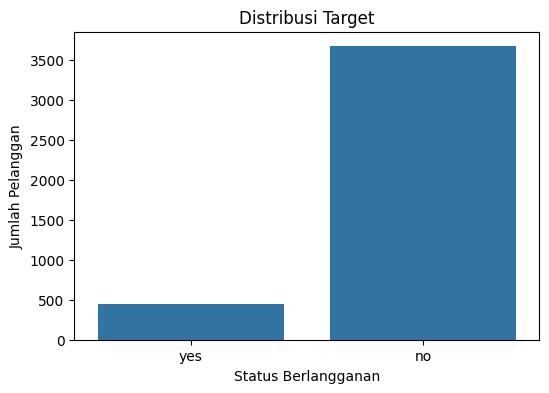

In [11]:
# Membuat Visualisasi Distribusi Target
plt.figure(figsize = (6, 4))
sns.countplot(data = df, x = 'y', order = ['yes', 'no'])

plt.title('Distribusi Target')
plt.xlabel('Status Berlangganan')
plt.ylabel('Jumlah Pelanggan')
plt.show()

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa terdapat 89% atau 3.668 orang yang tidak berlangganan deposito dan hanya sekitar 11% atau 451 orang saja yang berlangganan deposito. Sehingga dapat disimpulkan bahwa terdapat ketidakseimbangan nilai antara `yes` dan `no`. Sehingga diperlukan `SMOTENC` untuk mengatasi masalah data yang tidak seimbang (imbalanced data).

## 4.2 Melihat hubungan pekerjaan dengan status berlangganan deposito

In [12]:
# Menghitung persentase target berdasarkan pekerjaan
job_subscription = pd.crosstab(df['job'], df['y'], normalize = 'index') * 100

# Mengurutkan berdasarkan persentase pelanggan yang berlangganan
job_subscription = job_subscription.sort_values(by = 'yes', ascending = False)

job_subscription

y,no,yes
job,,
student,76.829268,23.170732
retired,77.108434,22.891566
unemployed,82.882883,17.117117
admin.,86.857708,13.142292
technician,88.422576,11.577424
unknown,89.743590,10.256410
housemaid,90.000000,10.000000
management,90.740741,9.259259
services,91.094148,8.905852


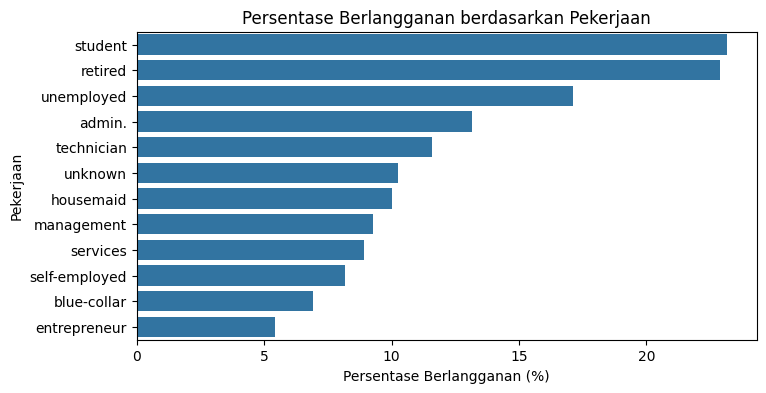

In [13]:
# Membuat visualisasi persentase berlangganan berdasarkan pekerjaan
plt.figure(figsize = (8, 4))
sns.barplot(x = job_subscription['yes'], y = job_subscription.index)

plt.title('Persentase Berlangganan berdasarkan Pekerjaan')
plt.xlabel('Persentase Berlangganan (%)')
plt.ylabel('Pekerjaan')
plt.show()

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa persentase pelanggan yang lebih banyak untuk berlangganan deposito adalah pelajar dengan persentase sekitar 23,17%. Lalu diikuti dengan pelanggan yang sudah pensiun yaitu sekitar 22,89%. Lalu untuk pelanggan yang paling sedikit untuk berlangganan deposito adalah pengusaha dengan persentase sekitar 5,4%. Sehingga dapat disimpulkan bahwa kemungkinan terdapat hubungan antara pekerjaan dengan status berlangganan deposito.

## 4.3 Melihat hubungan credit default dengan status berlangganan deposito

In [14]:
# Menghitung jumlah target berdasarkan status credit default
# Credit Default : Kredit yang gagal dibayar
default_count = pd.crosstab(df['default'], df['y'])
default_count

y,no,yes
default,,
no,2913,402
unknown,754,49
yes,1,0


In [15]:
# Menghitung persentase target berdasarkan status credit default
# Credit Default : Kredit yang gagal dibayar
default_subscription = pd.crosstab(df['default'], df['y'], normalize = 'index') * 100
default_subscription

y,no,yes
default,,
no,87.873303,12.126697
unknown,93.897883,6.102117
yes,100.000000,0.000000


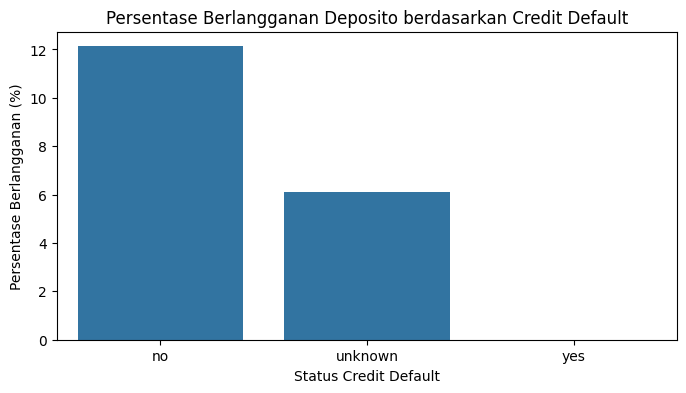

In [16]:
# Membuat visualisasi persentase berlangganan berdasarkan status credit default
plt.figure(figsize = (8, 4))
sns.barplot(x = default_subscription.index, y = default_subscription['yes'])

plt.title('Persentase Berlangganan Deposito berdasarkan Credit Default')
plt.xlabel('Status Credit Default')
plt.ylabel('Persentase Berlangganan (%)')
plt.show()

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa pelanggan yang tidak memiliki riwayat gagal bayar kredit mempunyai persentase berlangganan deposito yang paling tinggi yaitu sekitar 12,12%, sedangkan pelanggan yang tidak diketahui status riwayat gagal bayar kredit memiliki persentase berlangganan sekitar 6%. Lalu untuk persentase pelanggan yang memiliki riwayat gagal bayar hanya 1 orang dan dia tidak berlangganan deposito. Sehingga oleh karena itu belum bisa disimpulkan secara spesifik hubungan antara pelanggan yang memiliki riwayat gagal bayar kredit dengan status berlangganan deposito, dikarenakan datanya terlalu sedikit untuk orang yang memiliki riwayat gagal bayar kredit.

## 4.4 Melihat hubungan housing loan dengan status berlangganan deposito

In [17]:
# Menghitung jumlah target berdasarkan status housing loan
housing_count = pd.crosstab(df['housing'], df['y'])
housing_count

y,no,yes
housing,,
no,1637,202
unknown,96,9
yes,1935,240


In [18]:
# Menghitung persentase target berdasarkan status housing loan
housing_subscription = pd.crosstab(df['housing'], df['y'], normalize = 'index') * 100
housing_subscription

y,no,yes
housing,,
no,89.015769,10.984231
unknown,91.428571,8.571429
yes,88.965517,11.034483


Text(0, 0.5, 'Persentase Berlangganan')

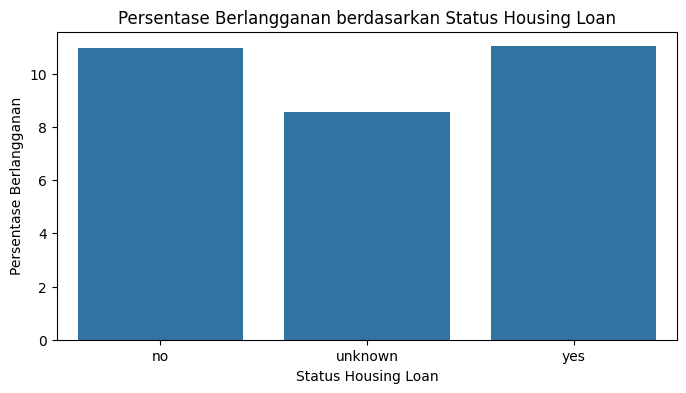

In [19]:
# Membuat visualisasi persentase berlangganan deposito
plt.figure(figsize = (8, 4))
sns.barplot(x = housing_subscription.index, y = housing_subscription['yes'])

plt.title('Persentase Berlangganan berdasarkan Status Housing Loan')
plt.xlabel('Status Housing Loan')
plt.ylabel('Persentase Berlangganan')

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa pelangganan yang memiliki pinjaman rumah mempunyai persentase berlangganan paling tinggi yaitu sekitar 11%. Lalu pelanggan yang tidak mempunyai pinjaman rumah mempunyai persentase berlangganan sebesar 10,98%. Lalu untuk pelanggan yang tidak diketahui status pinjaman rumah mempunyai persentase berlangganan deposito sebesar 8%. Perbedaan antara pelanggan yang memiliki pinjaman rumah dan pelanggan yang tidak memiliki pinjaman rumah tidak terlalu jauh, sehingga dapat disimpulkan bahwa status pinjaman rumah tidak menunjukkan perbedaan yang berarti dengan keputusan untuk berlangganan deposito.

## 4.5 Melihat hubungan personal loan dengan status berlangganan deposito

In [20]:
# Menghitung jumlah target berdasarkan status personal loan
loan_count = pd.crosstab(df['loan'], df['y'])
loan_count

y,no,yes
loan,,
no,2975,374
unknown,96,9
yes,597,68


In [21]:
# Menghitung persentase target berdasarkan status personal loan
loan_subscription = pd.crosstab(df['loan'], df['y'], normalize = 'index') * 100
loan_subscription

y,no,yes
loan,,
no,88.832487,11.167513
unknown,91.428571,8.571429
yes,89.774436,10.225564


Text(0, 0.5, 'Persentase Berlangganan (%)')

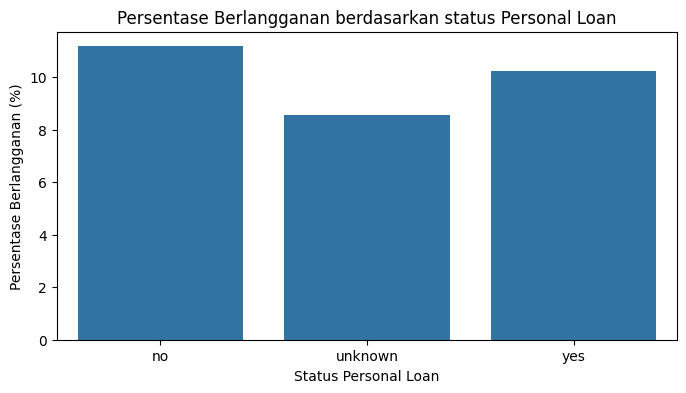

In [22]:
# Membuat visualisasi persentase berlangganan
plt.figure(figsize = (8, 4))
sns.barplot(x = loan_subscription.index, y = loan_subscription['yes'])

plt.title('Persentase Berlangganan berdasarkan status Personal Loan')
plt.xlabel('Status Personal Loan')
plt.ylabel('Persentase Berlangganan (%)')

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa pelanggan yang tidak memiliki pinjaman pribadi memiliki persentase berlangganan deposito yang paling tinggi yaitu sekitar 11,16%. Lalu untuk pelanggan yang memiliki pinjaman pribadi memiliki persentase berlangganan deposito sekitar 10,22%. Lalu untuk pelanggan yang tidak diketahui status pinjaman pribadinya memiliki persentase berlangganan deposito sekitar 8,57%. Perbedaan antara pelanggan yang tidak memiliki pinjaman pribadi dan pelanggan yang memiliki pinjaman pribadi tidak terlalu jauh, sehingga dapat disimpulkan bahwa status pinjaman pribadi tidak menunjukkan perbedaan yang berarti dengan keputusan untuk berlangganan deposito.

## 4.6 Melihat hubungan bulan melakukan kontak dengan status deposito

In [23]:
# Menghitung jumlah target berdasarkan bulan
month_count = pd.crosstab(df['month'], df['y'])
month_count

y,no,yes
month,,
apr,179,36
aug,572,64
dec,10,12
jul,652,59
jun,462,68
mar,20,28
may,1288,90
nov,403,43
oct,44,25


In [24]:
# Menghitung persentase target berdasarkan bulan
month_subscription = pd.crosstab(df['month'], df['y'], normalize = 'index') * 100

# Mengatur urutan bulan
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

month_subscription = month_subscription.reindex(month_order)
month_subscription

y,no,yes
month,,
mar,41.666667,58.333333
apr,83.255814,16.744186
may,93.468795,6.531205
jun,87.169811,12.830189
jul,91.701828,8.298172
aug,89.937107,10.062893
sep,59.375000,40.625000
oct,63.768116,36.231884
nov,90.358744,9.641256


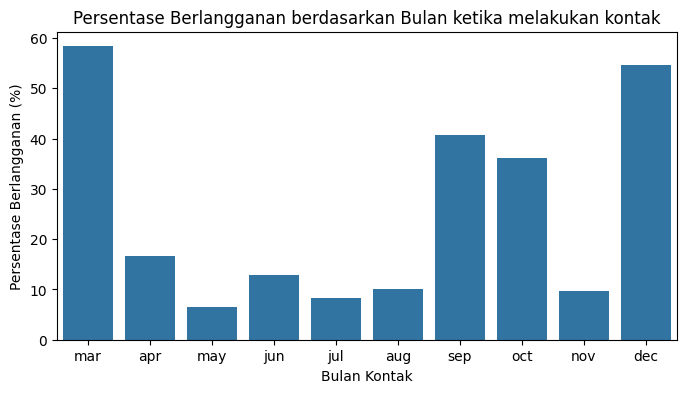

In [25]:
# Membuat visualisasi persentase berlangganan
plt.figure(figsize = (8, 4))
sns.barplot(x = month_subscription.index, y = month_subscription['yes'])

plt.title('Persentase Berlangganan berdasarkan Bulan ketika melakukan kontak')
plt.xlabel('Bulan Kontak')
plt.ylabel('Persentase Berlangganan (%)')
plt.show()

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa pada bulan Maret memiliki persentase berlangganan deposito yang paling tinggi sekitar 58,33%. Lalu diikuti dengan bulan Desember yaitu sekitar 54,54%. Lalu bulan Mei memiliki persentase berlangganan deposito yang paling rendah yaitu sekitar 6,53%. Sehingga dapat disimpulkan bahwa pada bulan Maret dan bulan Desember memiliki tingkat persentase paling tinggi untuk berlangganan deposito.

## 4.7 Melihat hubungan hari melakukan kontak dengan status berlangganan deposito

In [26]:
# Menghitung jumlah target berdasarkan hari
day_count = pd.crosstab(df['day_of_week'], df['y'])
day_count

y,no,yes
day_of_week,,
fri,685,83
mon,757,98
thu,764,96
tue,750,91
wed,712,83


In [27]:
# Menghitung persentase target berdasarkan hari
day_subscription = pd.crosstab(df['day_of_week'], df['y'], normalize = 'index') * 100

# Mengatur urutan hari
day_order = ['mon', 'tue', 'wed', 'thu', 'fri']

day_subscription = day_subscription.reindex(day_order)
day_subscription

y,no,yes
day_of_week,,
mon,88.538012,11.461988
tue,89.179548,10.820452
wed,89.559748,10.440252
thu,88.837209,11.162791
fri,89.192708,10.807292


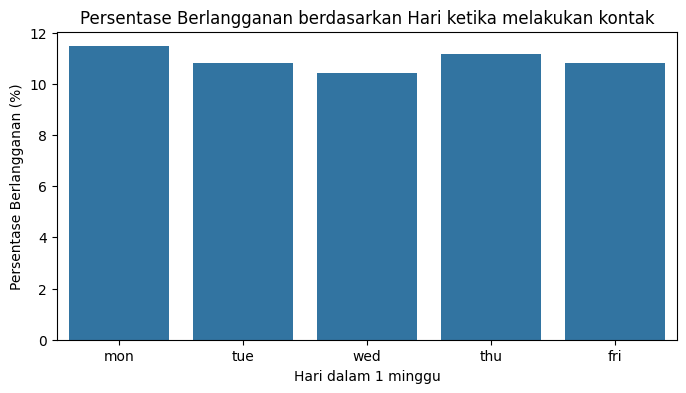

In [28]:
# Membuat visualisasi persentase berlangganan
plt.figure(figsize = (8, 4))
sns.barplot(x = day_subscription.index, y = day_subscription['yes'])

plt.title('Persentase Berlangganan berdasarkan Hari ketika melakukan kontak')
plt.xlabel('Hari dalam 1 minggu')
plt.ylabel('Persentase Berlangganan (%)')
plt.show()

**Data Insight :** Berdasarkan hasil analisis dan visualisasi diatas didapatkan hasil bahwa pada hari senin memiliki persentase berlangganan yang paling tinggi yaitu sekitar 11,46%. Lalu diikuti dengan hari Kamis yaitu sekitar 11,16%. Lalu untuk hari Rabu memiliki persentase berlangganan yang paling rendah yaitu sekitar 10,44%. Perbedaan persentase antar hari tidak terlalu beda jauh sehingga dapat disimpulkan bahwa hari tidak menunjukkan perbedaan dalam berlangganan deposito.

# 5. Feature Engineering

## 5.1 Split Data

In [29]:
# Membagi dataset menjadi train set dan test set
X_train, X_test = train_test_split(df, test_size = 0.2, random_state = 42, stratify = df['y'])

In [30]:
# Memisahkan target dari data train
y_train = X_train.y
X_train = X_train.drop(['y'], axis = 1)

# Memisahkan target dari data test
y_test = X_test.y
X_test = X_test.drop(['y'], axis = 1)

## 5.2 Cardinality

In [31]:
obj_col = X_train.select_dtypes(include = ['object'])
for cat in obj_col:
  count = len(X_train[cat].unique())
  print(f"Cardinality of column {cat} is {count}")

Cardinality of column job is 12
Cardinality of column marital is 4
Cardinality of column education is 8
Cardinality of column default is 3
Cardinality of column housing is 3
Cardinality of column loan is 3
Cardinality of column contact is 2
Cardinality of column month is 10
Cardinality of column day_of_week is 5
Cardinality of column poutcome is 3


## 5.3 Handling Outliers

### 5.3.1 Handling Outliers in Train Set

In [32]:
# Menampilkan statistik deskriptif
X_train.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,3295.000000,3295.000000,3295.000000,135.000000,3295.000000,3295.000000,3295.000000,3295.000000,3295.000000,3295.000000
mean,40.184825,256.211533,2.513505,5.807407,0.203035,0.068437,93.574734,-40.404825,3.608195,5165.577724
std,10.373130,256.892291,2.541170,3.819620,0.558961,1.568603,0.582684,4.632171,1.738085,74.286875
min,18.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,32.000000,102.000000,1.000000,3.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,38.000000,180.000000,2.000000,6.000000,0.000000,1.100000,93.444000,-41.800000,4.857000,5191.000000
75%,47.000000,315.000000,3.000000,6.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,86.000000,3643.000000,35.000000,19.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [33]:
# Menghitung persentase outlier
num_train = X_train._get_numeric_data()
for k, v in num_train.items():
  q1 = v.quantile(0.25)
  q3 = v.quantile(0.75)
  iqr = q3 - q1
  v_col = v[(v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)]
  perc = np.shape(v_col)[0] * 100.0 / np.shape(num_train)[0]
  print("Column %s outliers = %.2f%%" % (k, perc))

Column age outliers = 1.00%
Column duration outliers = 7.19%
Column campaign outliers = 5.49%
Column pdays outliers = 0.46%
Column previous outliers = 15.33%
Column emp.var.rate outliers = 0.00%
Column cons.price.idx outliers = 0.00%
Column cons.conf.idx outliers = 1.21%
Column euribor3m outliers = 0.00%
Column nr.employed outliers = 0.00%


In [34]:
# Handling nilai outlier dengan membatasi nilainya
windsoriser = Winsorizer(capping_method = 'iqr', tail = 'both', fold = 1.5, variables = ['age', 'duration', 'campaign'])

windsoriser.fit(X_train)

X_train = windsoriser.transform(X_train)
X_test = windsoriser.transform(X_test)

## 5.4 Handling Missing Values

In [35]:
# Mengecek jumlah missing value di X_train
X_train.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


## 5.5 Feature Selection using Feature Importance

In [36]:
# Mengubah target menjadi angka
label = LabelEncoder()
y_train = label.fit_transform(y_train)
y_test = label.transform(y_test)

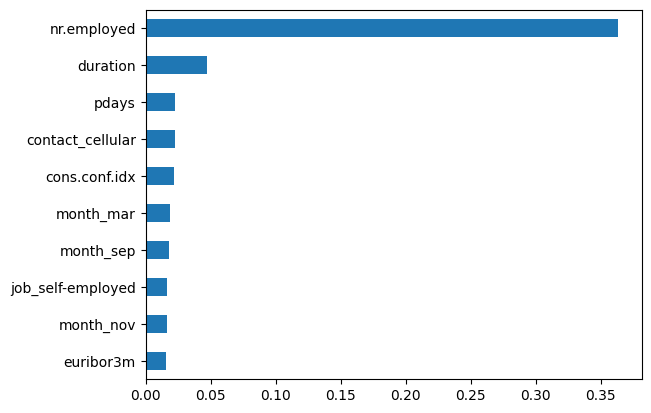

In [37]:
# Membuat Model Sementara
model = XGBClassifier()

# Mengubah Sementara Fitur Kategorikal menggunakan One-Hot Encoding
X_train_ohe = pd.get_dummies(X_train, columns = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome'])
y_train_ohe = y_train.copy()

# Melatih model sementara
model.fit(X_train_ohe, y_train_ohe)

# Menampilkan 10 fitur terpenting
feat_importances = pd.Series(model.feature_importances_, index = X_train_ohe.columns)
feat_importances.nlargest(10).plot(kind = 'barh').invert_yaxis()

In [38]:
# Menghapus fitur Duration di data train
X_train.drop(['duration'], axis = 1, inplace = True)

In [39]:
# Menghapus fitur Duration di data test
X_test.drop(['duration'], axis = 1, inplace = True)

In [40]:
# Melihat kolom X_train dan X_test
X_train.columns, X_test.columns

(Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
        'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
        'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
        'euribor3m', 'nr.employed'],
       dtype='object'),
 Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
        'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
        'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
        'euribor3m', 'nr.employed'],
       dtype='object'))

In [41]:
# Menentukan kolom numerik dan kategorikal
num_col = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
encoded_column = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

## 5.6 Column Transformer

### 5.6.1 Column Transformer untuk mengisi missing value

In [42]:
# Buat Column Transformer untuk mengisi missing value
imputation = ColumnTransformer([
    ('numerical', Pipeline([
        ('imputer', SimpleImputer(strategy = 'median'))
    ]), num_col),

    ('categorical_nominal', Pipeline([
        ('imputer', SimpleImputer(strategy = 'most_frequent'))
    ]), encoded_column)
], verbose_feature_names_out = False)

imputation.set_output(transform = 'pandas')

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['age', 'campaign', 'pdays', 'previous',
                                  'emp.var.rate', 'cons.price.idx',
                                  'cons.conf.idx', 'euribor3m',
                                  'nr.employed']),
                                ('categorical_nominal',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent'))]),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'day_of_week', 'poutcome'])],
                  verbose_feature_names_out=False)

### 5.6.2 Column Transformer untuk scaling dan encoding

In [43]:
# Buat Column Transformer untuk scaling dan encoding
preprocessing = ColumnTransformer([
    ('numerical', Pipeline([
        ('scaler', MinMaxScaler())
    ]), num_col),

    ('categorical_nominal', Pipeline([
        ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
    ]), encoded_column)
])

# 6. Model Definition

In [44]:
# Buat Pipeline untuk KNN
pipe_knn = ImbPipeline([
    ('imputer', imputation),
    ('smotenc', SMOTENC([9, 10, 11, 12, 13, 14, 15, 16, 17, 18], random_state = 38)),
    ('transformer', preprocessing),
    ('classifier', KNeighborsClassifier())
])

# Membuat Pipeline untuk SVM
pipe_svm = ImbPipeline([
    ('imputer', imputation),
    ('smotenc', SMOTENC([9, 10, 11, 12, 13, 14, 15, 16, 17, 18], random_state = 38)),
    ('transformer', preprocessing),
    ('classifier', SVC())
])

# Membuat pipeline untuk Decision Tree
pipe_dt = ImbPipeline([
    ('imputer', imputation),
    ('smotenc', SMOTENC([9, 10, 11, 12, 13, 14, 15, 16, 17, 18], random_state = 38)),
    ('transformer', preprocessing),
    ('classifier', DecisionTreeClassifier())
])

# Membuat pipeline untuk Random Forest
pipe_rf = ImbPipeline([
    ('imputer', imputation),
    ('smotenc', SMOTENC([9, 10, 11, 12, 13, 14, 15, 16, 17, 18], random_state = 38)),
    ('transformer', preprocessing),
    ('classifier', RandomForestClassifier())
])

# Membuat pipeline untuk XGBoost
pipe_xgb = ImbPipeline([
    ('imputer', imputation),
    ('smotenc', SMOTENC([9, 10, 11, 12, 13, 14, 15, 16, 17, 18], random_state = 38)),
    ('transformer', preprocessing),
    ('classifier', XGBClassifier())
])

# 7. Base Model Training

## 7.1 K-Nearest Neighbors (KNN)

In [45]:
pipe_knn.fit(X_train, y_train)

Pipeline(steps=[('imputer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['job', 'm...
                                                                   MinMaxScaler())]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier', KNeighborsClassifier())])

## 7.2 Support Vector Machine (SVM)

In [46]:
pipe_svm.fit(X_train, y_train)

Pipeline(steps=[('imputer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['job', 'm...
                                                  Pipeline(steps=[('scaler',
                                                                   MinMaxScaler())]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier', SVC())])

## 7.3 Decision Tree Classifier

In [47]:
pipe_dt.fit(X_train, y_train)

Pipeline(steps=[('imputer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['job', 'm...
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier', DecisionTreeClassifier())])

## 7.4 Random Forest Classifier

In [48]:
pipe_rf.fit(X_train, y_train)

Pipeline(steps=[('imputer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['job', 'm...
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier', RandomForestClassifier())])

## 7.5 XGBoost Classifier

In [49]:
pipe_xgb.fit(X_train, y_train)

Pipeline(steps=[('imputer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['job', 'm...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

# 8. Model Evaluation

## 8.1 K-Nearest Neighbors (KNN)

In [50]:
f1_train_cross_val = cross_validate(pipe_knn, X_train, y_train, cv = 3, return_train_score = True, scoring = 'f1')

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [0.50728863 0.49707602 0.49507736]
F1 Score - Mean - Cross Validation For Train set:  0.4998140029887572
F1 Score - Std - Cross Validation For Train set:  0.005347971688706375
------
F1 Score - All - Cross Validation  :  [0.3172043  0.31635389 0.30366492]
F1 Score - Mean - Cross Validation :  0.31240770331356704
F1 Score - Std - Cross Validation  :  0.006191821308846171


## 8.2 Support Vector Machine (SVM)

In [51]:
f1_train_cross_val = cross_validate(pipe_svm, X_train, y_train, cv = 3, return_train_score = True, scoring = 'f1')

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [0.54121864 0.52220249 0.51785714]
F1 Score - Mean - Cross Validation For Train set:  0.5270927558428274
F1 Score - Std - Cross Validation For Train set:  0.01014481519852453
------
F1 Score - All - Cross Validation  :  [0.35424354 0.32601881 0.41696113]
F1 Score - Mean - Cross Validation :  0.3657411606516345
F1 Score - Std - Cross Validation  :  0.0380067792160245


## 8.3 Decision Tree

In [52]:
f1_train_cross_val = cross_validate(pipe_dt, X_train, y_train, cv = 3, return_train_score = True, scoring = 'f1')

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [1. 1. 1.]
F1 Score - Mean - Cross Validation For Train set:  1.0
F1 Score - Std - Cross Validation For Train set:  0.0
------
F1 Score - All - Cross Validation  :  [0.3125     0.32298137 0.34782609]
F1 Score - Mean - Cross Validation :  0.32776915113871635
F1 Score - Std - Cross Validation  :  0.014813850872633203


## 8.4 Random Forest Classifier

In [53]:
f1_train_cross_val = cross_validate(pipe_rf, X_train, y_train, cv = 3, return_train_score = True, scoring = 'f1')

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [1. 1. 1.]
F1 Score - Mean - Cross Validation For Train set:  1.0
F1 Score - Std - Cross Validation For Train set:  0.0
------
F1 Score - All - Cross Validation  :  [0.39810427 0.39166667 0.4573991 ]
F1 Score - Mean - Cross Validation :  0.4157233450695079
F1 Score - Std - Cross Validation  :  0.02958617106434439


## 8.5 XGBoost Classifier

In [54]:
f1_train_cross_val = cross_validate(pipe_xgb, X_train, y_train, cv = 3, return_train_score = True, scoring = 'f1')

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [0.95913978 0.95010846 0.95010846]
F1 Score - Mean - Cross Validation For Train set:  0.9531189015619775
F1 Score - Std - Cross Validation For Train set:  0.004257407469742889
------
F1 Score - All - Cross Validation  :  [0.40816327 0.35443038 0.37914692]
F1 Score - Mean - Cross Validation :  0.38058018816141254
F1 Score - Std - Cross Validation  :  0.0219597577714546


## 8.6 Base Model Comparison

In [55]:
# Performa untuk Baseline Model
models = {
    'K-Nearest Neighbors (KNN)' : pipe_knn,
    'Support Vector Machine (SVM)' : pipe_svm,
    'Decision Tree'       : pipe_dt,
    'Random Forest'       : pipe_rf,
    'XGBoost'             : pipe_xgb
}

df_cross_val = pd.DataFrame(columns = models.keys(),
                            index=['Train Mean', 'Train Std', 'Test Mean', 'Test Std'])

for name, model in models.items():
    cv_results = cross_validate(model, X_train, y_train, cv=3,
                                return_train_score=True,
                                scoring="f1")

    df_cross_val.loc['Train Mean', name] = cv_results['train_score'].mean()
    df_cross_val.loc['Train Std',  name] = cv_results['train_score'].std()
    df_cross_val.loc['Test Mean',  name] = cv_results['test_score'].mean()
    df_cross_val.loc['Test Std',   name] = cv_results['test_score'].std()

In [56]:
df_cross_val

,K-Nearest Neighbors (KNN),Support Vector Machine (SVM),Decision Tree,Random Forest,XGBoost
Train Mean,0.499814,0.527093,1.0,1.0,0.953119
Train Std,0.005348,0.010145,0.0,0.0,0.004257
Test Mean,0.312408,0.365741,0.307509,0.408183,0.38058
Test Std,0.006192,0.038007,0.022496,0.030651,0.02196


# 9. Hyperparameter Tuning

In [57]:
# Parameter Tuning

param_rf = {
    'transformer__numerical__scaler' : [StandardScaler(), MinMaxScaler()],
    'classifier__n_estimators' : [1,10,100],
    'classifier__max_depth' : np.arange(4,8,2),
    'classifier__min_samples_split' : np.arange(4, 8, 5)
}

# 10. Model Optimization Evaluation

## 10.1 Random Forest Classifier

In [58]:
grid_rf = GridSearchCV(pipe_rf, param_rf, cv = 5).fit(X_train, y_train)

In [59]:
print('Train Set Score : ', grid_rf.score(X_train, y_train))
print('Test Set Score : ', grid_rf.score(X_test, y_test))

Train Set Score :  0.876783004552352
Test Set Score :  0.8822815533980582


In [60]:
best_param_rf = grid_rf.best_params_
print(best_param_rf)
print('\n')
best_pipe_rf = grid_rf.best_estimator_
print(best_pipe_rf)

{'classifier__max_depth': np.int64(6), 'classifier__min_samples_split': np.int64(4), 'classifier__n_estimators': 100, 'transformer__numerical__scaler': StandardScaler()}


Pipeline(steps=[('imputer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categorical_nominal',
                                                  Pipeline(steps=[('imputer',
                            

In [61]:
y_pred_test = best_pipe_rf.predict(X_test)

In [62]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.94      0.93      0.93       734
           1       0.46      0.48      0.47        90

    accuracy                           0.88       824
   macro avg       0.70      0.70      0.70       824
weighted avg       0.88      0.88      0.88       824



# 11. Model After Tuning Comparison

In [63]:
# Performa model setelah dilakukan tuning
models = {
    'Random Forest' : best_pipe_rf
}

model_tuning = pd.DataFrame(columns = models.keys(),
                            index=['Train Accuracy', 'Train F1-Score',
                                   'Test Accuracy',  'Test F1-Score'])

for name, model in models.items():
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)

    # Train scores
    model_tuning.loc['Train Accuracy', name]  = accuracy_score(y_train, y_pred_train)
    model_tuning.loc['Train F1-Score', name] = f1_score(y_train, y_pred_train)

    # Test scores
    model_tuning.loc['Test Accuracy', name]  = accuracy_score(y_test, y_pred_test)
    model_tuning.loc['Test F1-Score', name] = f1_score(y_test, y_pred_test)


In [64]:
# Performa setelah tuning
model_tuning

,Random Forest
Train Accuracy,0.876783
Train F1-Score,0.508475
Test Accuracy,0.882282
Test F1-Score,0.469945


In [65]:
# Performa baseline model: F1 Score
df_cross_val

,K-Nearest Neighbors (KNN),Support Vector Machine (SVM),Decision Tree,Random Forest,XGBoost
Train Mean,0.499814,0.527093,1.0,1.0,0.953119
Train Std,0.005348,0.010145,0.0,0.0,0.004257
Test Mean,0.312408,0.365741,0.307509,0.408183,0.38058
Test Std,0.006192,0.038007,0.022496,0.030651,0.02196


# 12. Save Model

In [ ]:
# Menyimpan model Random Forest terbaik
pickle.dump(best_pipe_rf, open('model.pkl', 'wb'))

# Menyimpan Winsorizer
pickle.dump(windsoriser, open('windsoriser.pkl', 'wb'))

# Menyimpan Label Encoder
pickle.dump(label, open('label_encoder.pkl', 'wb'))

# 13. Pengambilan Kesimpulan

Dari hasil analisis diatas didapatkan hasil bahwa dataset yang dipakai itu tidak seimbang yaitu sekitar 89% yang tidak ingin berlangganan deposito, sedangkan hanya 11% saja yang ingin berlangganan deposito.

Lalu setelah dilakukan analisis dan visualisasi pada EDA didapatkan hasil bahwa untuk fitur job, default dan month memiliki hubungan yang kuat dengan keputusan berlangganan deposito dibandingkan fitur housing, loan dan day_of_week.

Lalu dari 5 model baseline yaitu KNN, SVM, Decision Tree, Random Forest dan XGBoost didapatkan hasil bahwa model yang paling bagus adalah Random Forest, karena Random Forest memberikan F1-Score yang paling baik di antara lainnya yaitu sekitar 0,407. Lalu setelah di tuning Random Forest menghasilkan akurasi test sebesar 87,86%. Sehingga hasilnya cukup bagus.